# 01 像素、采样、量化、颜色与直方图
学习顺序：小矩阵手算 → 对真实照片执行同样操作 → 比较输入输出。
采样决定空间取样的密度；量化决定幅值可用的离散等级。两者不能混为“图片有多少种颜色”。


In [1]:
from pathlib import Path
import sys
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "course_utils.py").exists()), None)
if root is None:
    raise RuntimeError("请在完整的 cv-beginner-course 项目里打开 Notebook")
if str(root) not in sys.path: sys.path.insert(0, str(root))
from course_utils import setup, device, show_images, save_figure, ROOT
ROOT = setup(seed=42)
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch
print("计算设备:", device())


计算设备: cuda


## 1 输入一个 5×5 灰度矩阵
8 位单通道可取 0–255，共 256 个值；RGB 图像是三个这样的通道。像素数不等于实际出现的颜色数量。


[[  0  30  60  90 120]
 [ 30  60  90 120 150]
 [ 60  90 120 150 180]
 [ 90 120 150 180 210]
 [120 150 180 210 255]]


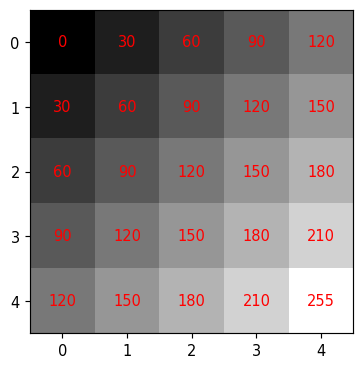

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/01_matrix.png')

In [2]:
a = np.array([[0,30,60,90,120],[30,60,90,120,150],[60,90,120,150,180],
              [90,120,150,180,210],[120,150,180,210,255]], dtype=np.uint8)
print(a)
fig,ax=plt.subplots(figsize=(5,4)); ax.imshow(a,cmap="gray",vmin=0,vmax=255)
for (y,x),value in np.ndenumerate(a): ax.text(x,y,str(value),ha="center",va="center",color="red")
save_figure("01_matrix")


## 2 空间采样与幅值量化
采样每隔两个位置取一个值；量化将 [0,255] 分成 4 个区间，输出 0、85、170、255。


采样后:
 [[  0  60 120]
 [ 60 120 180]
 [120 180 255]] 
量化后:
 [[  0   0   0  85  85]
 [  0   0  85  85 170]
 [  0  85  85 170 170]
 [ 85  85 170 170 255]
 [ 85 170 170 255 255]]


/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 36755 (\N{CJK UNIFIED IDEOGRAPH-8F93}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 20837 (\N{CJK UNIFIED IDEOGRAPH-5165}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 31354 (\N{CJK UNIFIED IDEOGRAPH-7A7A}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 38388 (\N{CJK UNIFIED IDEOGRAPH-95F4}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 37319 (\N{CJK UNIFIED IDEOGRAPH-91C7}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 26679 (\N{CJK UNIFIED IDEOGRAPH-6837}) missing from font(s) DejaVu Sans.
 

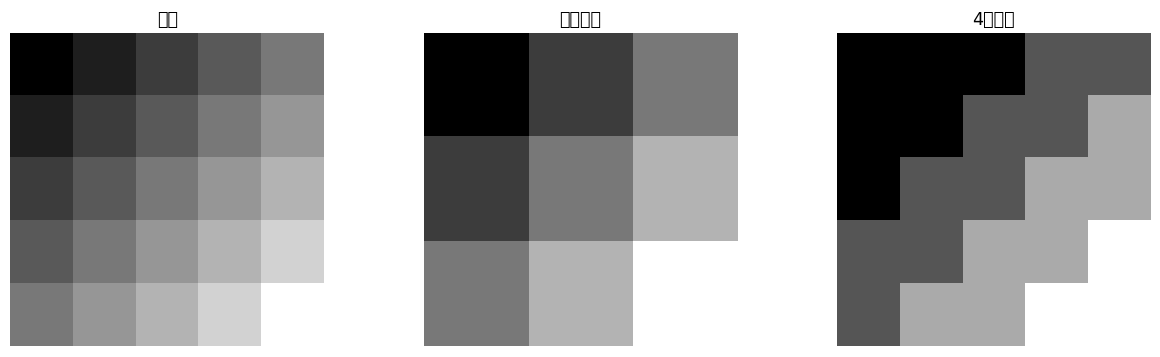

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/01_sampling_quantization.png')

In [3]:
sampled = a[::2, ::2]
quantized = (np.floor(a.astype(float)/64).clip(0,3) * 85).astype(np.uint8)
print("采样后:\n",sampled, "\n量化后:\n",quantized)
assert len(np.unique(quantized)) <= 4
show_images([a,sampled,quantized],["输入","空间采样","4级量化"]); save_figure("01_sampling_quantization")


## 3 对真实照片采样与量化
最近邻放大只是把低分辨率像素画大，没有恢复原始细节。


/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 20877 (\N{CJK UNIFIED IDEOGRAPH-518D}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 25918 (\N{CJK UNIFIED IDEOGRAPH-653E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 22823 (\N{CJK UNIFIED IDEOGRAPH-5927}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 27599 (\N{CJK UNIFIED IDEOGRAPH-6BCF}) missing from font(s) DejaVu Sans.
 

/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20877 (\N{CJK UNIFIED IDEOGRAPH-518D}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 25918 (\N{CJK UNIFIED IDEOGRAPH-653E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/p

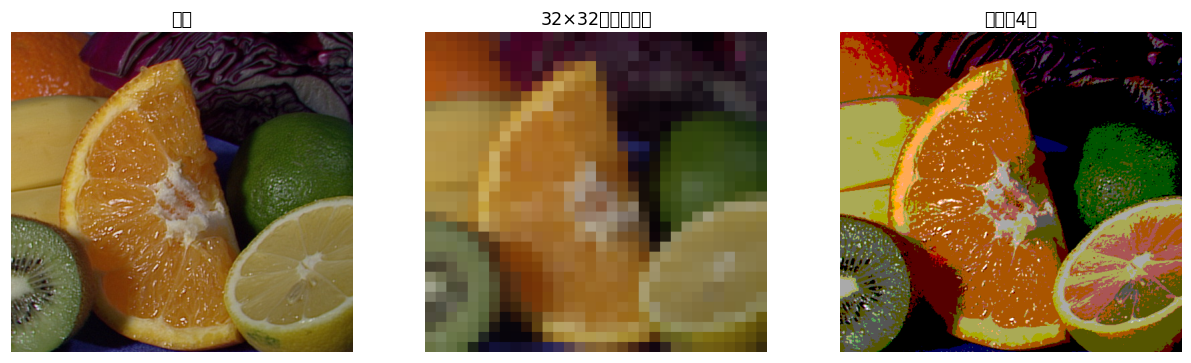

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/01_photo_sampling.png')

In [4]:
bgr=cv2.imread(str(ROOT/"assets/photos/fruits.jpg")); assert bgr is not None
rgb=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
low=cv2.resize(rgb,(32,32),interpolation=cv2.INTER_AREA)
up=cv2.resize(low,(rgb.shape[1],rgb.shape[0]),interpolation=cv2.INTER_NEAREST)
q=(np.floor(rgb.astype(float)/64).clip(0,3)*85).astype(np.uint8)
show_images([rgb,up,q],["原图","32×32采样再放大","每通道4级"]); save_figure("01_photo_sampling")


## 4 灰度、HSV 与直方图
OpenCV 的常用灰度近似为 0.299R+0.587G+0.114B（实际舍入可差一个灰度值）。HSV 是颜色表示方式，不代表“物理层面和画家层面”两个严格类别。
对 uint8 的 OpenCV HSV，H 通常范围 0–179，S、V 为 0–255。


/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 28784 (\N{CJK UNIFIED IDEOGRAPH-7070}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 33394 (\N{CJK UNIFIED IDEOGRAPH-8272}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 30456 (\N{CJK UNIFIED IDEOGRAPH-76F8}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 26174 (\N{CJK UNIFIED IDEOGRAPH-663E}) missing from font(s) DejaVu Sans.
 

灰度局部矩阵:
 [[77 78 79 78]
 [82 82 81 79]
 [82 81 79 77]
 [81 80 78 76]]
手算最大舍入差: 1


/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 26126 (\N{CJK UNIFIED IDEOGRAPH-660E}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')


/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 28784 (\N{CJK UNIFIED IDEOGRAPH-7070}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 33394 (\N{CJK UNIFIED IDEOGRAPH-8272}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 30456 (\N{CJK UNIFIED IDEOGRAPH-76F8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/p

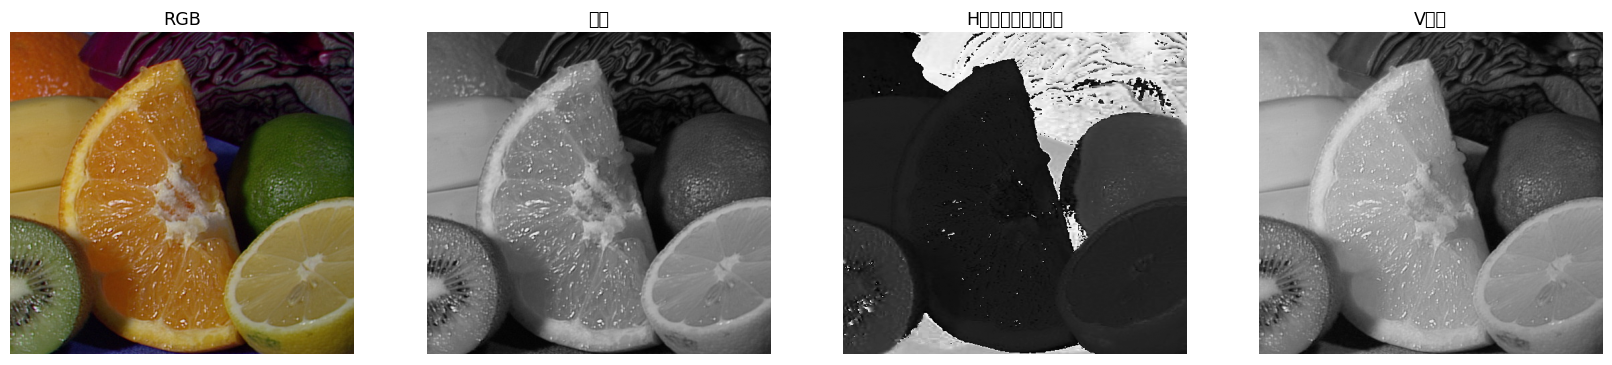

/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 20687 (\N{CJK UNIFIED IDEOGRAPH-50CF}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 32032 (\N{CJK UNIFIED IDEOGRAPH-7D20}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 20010 (\N{CJK UNIFIED IDEOGRAPH-4E2A}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 30452 (\N{CJK UNIFIED IDEOGR

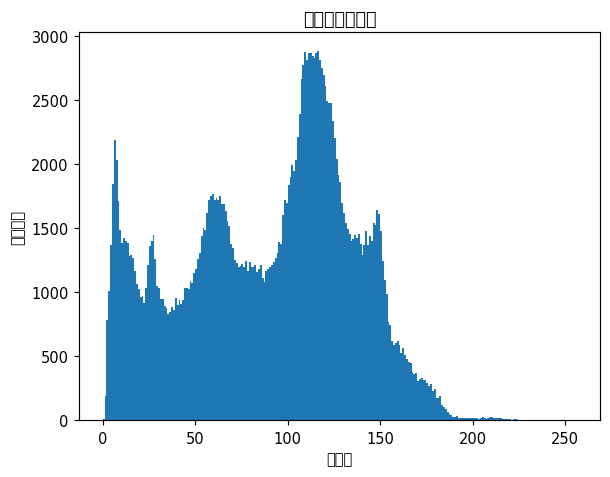

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/01_histogram.png')

In [5]:
gray=cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
hsv=cv2.cvtColor(rgb,cv2.COLOR_RGB2HSV)
manual=np.round(rgb@np.array([0.299,0.587,0.114])).astype(np.uint8)
print("灰度局部矩阵:\n",gray[:4,:4]); print("手算最大舍入差:",np.abs(gray.astype(int)-manual.astype(int)).max())
show_images([rgb,gray,hsv[:,:,0],hsv[:,:,2]],["RGB","灰度","H色相（灰度显示）","V明度"]); save_figure("01_color_channels")
fig,ax=plt.subplots(); ax.hist(gray.ravel(),bins=256,range=(0,256)); ax.set(xlabel="灰度值",ylabel="像素个数",title="输入灰度直方图")
save_figure("01_histogram")


## 5 亮度与对比度
`y=clip(alpha*x+beta)`：beta 平移灰度，alpha 改变对比度。uint8 直接加法可能溢出，先转浮点再截断。


输入/亮度/对比度的局部值: [77 78 79 78 78] [127 128 129 128 128] [46 48 49 48 48]


/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 24515 (\N{CJK UNIFIED IDEOGRAPH-5FC3}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 24515 (\N{CJK UNIFIED IDEOGRAPH-5FC3}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')


/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 24515 (\N{CJK UNIFIED IDEOGRAPH-5FC3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


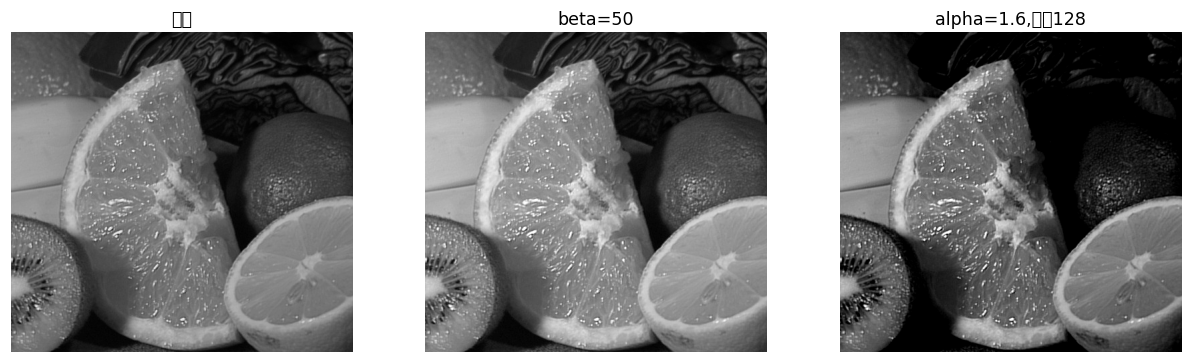

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/01_brightness_contrast.png')

In [6]:
brighter=np.clip(gray.astype(float)+50,0,255).astype(np.uint8)
contrast=np.clip((gray.astype(float)-128)*1.6+128,0,255).astype(np.uint8)
print("输入/亮度/对比度的局部值:",gray[0,:5],brighter[0,:5],contrast[0,:5])
show_images([gray,brighter,contrast],["输入","beta=50","alpha=1.6,中心128"]); save_figure("01_brightness_contrast")


## 6 练习与核对
手算 `a[2,2]` 的4邻域和8邻域；比较 16、32、64 像素采样；比较每通道 2、4、8 级量化。
应看到空间分辨率降低与色阶减少产生不同失真。
参考：[OpenCV 颜色空间](https://docs.opencv.org/4.x/df/d9d/tutorial_py_colorspaces.html)。
